In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

df = pd.read_csv('city_day.csv')


In [12]:
print('Shape:', df.shape)
print('Cities:', df['City'].nunique())
print('Date range:', df['Date'].min(), 'to', df['Date'].max())
print(df['City'].value_counts().head())

Shape: (29531, 16)
Cities: 26
Date range: 2015-01-01 to 2020-07-01
City
Ahmedabad    2009
Bengaluru    2009
Chennai      2009
Delhi        2009
Lucknow      2009
Name: count, dtype: int64


In [13]:
print('Shape:', df.shape)
display(df.head())


Shape: (29531, 16)


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [14]:
df.info()
display(df.describe().T)


<class 'pandas.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        29531 non-null  str    
 1   Date        29531 non-null  str    
 2   PM2.5       24933 non-null  float64
 3   PM10        18391 non-null  float64
 4   NO          25949 non-null  float64
 5   NO2         25946 non-null  float64
 6   NOx         25346 non-null  float64
 7   NH3         19203 non-null  float64
 8   CO          27472 non-null  float64
 9   SO2         25677 non-null  float64
 10  O3          25509 non-null  float64
 11  Benzene     23908 non-null  float64
 12  Toluene     21490 non-null  float64
 13  Xylene      11422 non-null  float64
 14  AQI         24850 non-null  float64
 15  AQI_Bucket  24850 non-null  str    
dtypes: float64(13), str(3)
memory usage: 3.6 MB


,count,mean,std,min,25%,50%,75%,max
PM2.5,24933.0,67.450578,64.661449,0.04,28.820,48.57,80.5900,949.99
PM10,18391.0,118.127103,90.605110,0.01,56.255,95.68,149.7450,1000.00
NO,25949.0,17.574730,22.785846,0.02,5.630,9.89,19.9500,390.68
NO2,25946.0,28.560659,24.474746,0.01,11.750,21.69,37.6200,362.21
NOx,25346.0,32.309123,31.646011,0.00,12.820,23.52,40.1275,467.63
NH3,19203.0,23.483476,25.684275,0.01,8.580,15.85,30.0200,352.89
CO,27472.0,2.248598,6.962884,0.00,0.510,0.89,1.4500,175.81
SO2,25677.0,14.531977,18.133775,0.01,5.670,9.16,15.2200,193.86
O3,25509.0,34.491430,21.694928,0.01,18.860,30.84,45.5700,257.73
Benzene,23908.0,3.280840,15.811136,0.00,0.120,1.07,3.0800,455.03


In [15]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(1)
display(pd.DataFrame({'missing': missing, 'percent': missing_pct}).sort_values('percent', ascending=False))



,missing,percent
Xylene,18109,61.3
PM10,11140,37.7
NH3,10328,35.0
Toluene,8041,27.2
Benzene,5623,19.0
AQI,4681,15.9
AQI_Bucket,4681,15.9
PM2.5,4598,15.6
NOx,4185,14.2
O3,4022,13.6


In [16]:
print('Duplicate rows:', df.duplicated().sum())
print('Duplicate City+Date:', df.duplicated(['City', 'Date']).sum())
print('Number of cities:', df['City'].nunique())
print('Date range:', df['Date'].min(), 'to', df['Date'].max())
print()
print(df['City'].value_counts())


Duplicate rows: 0
Duplicate City+Date: 0
Number of cities: 26
Date range: 2015-01-01 to 2020-07-01

City
Ahmedabad             2009
Bengaluru             2009
Chennai               2009
Delhi                 2009
Lucknow               2009
Mumbai                2009
Hyderabad             2006
Patna                 1858
Gurugram              1679
Visakhapatnam         1462
Amritsar              1221
Jorapokhar            1169
Jaipur                1114
Thiruvananthapuram    1112
Amaravati              951
Brajrajnagar           938
Talcher                925
Kolkata                814
Guwahati               502
Coimbatore             386
Shillong               310
Chandigarh             304
Bhopal                 289
Ernakulam              162
Kochi                  162
Aizawl                 113
Name: count, dtype: int64


In [17]:
coverage = df.groupby('City')['Date'].agg(['min', 'max', 'count'])
display(coverage)


,min,max,count
City,,,
Ahmedabad,2015-01-01,2020-07-01,2009
Aizawl,2020-03-11,2020-07-01,113
Amaravati,2017-11-24,2020-07-01,951
Amritsar,2017-02-27,2020-07-01,1221
Bengaluru,2015-01-01,2020-07-01,2009
Bhopal,2019-09-17,2020-07-01,289
Brajrajnagar,2017-12-07,2020-07-01,938
Chandigarh,2019-09-02,2020-07-01,304
Chennai,2015-01-01,2020-07-01,2009


In [18]:
df['Date'] = pd.to_datetime(df['Date'])
print(df['Date'].dtype)



datetime64[us]


In [19]:
df = df.drop(columns=['Xylene'])
print(df.shape)


(29531, 15)


In [20]:
rows_before = len(df)
print('AQI_Bucket missing where AQI missing:', df[df['AQI'].isnull()]['AQI_Bucket'].isnull().all())
df = df.dropna(subset=['AQI']).copy()
print('Rows before:', rows_before, '| Rows after:', len(df))



AQI_Bucket missing where AQI missing: True
Rows before: 29531 | Rows after: 24850


In [21]:
pollutants = ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene']

for col in pollutants:
    df[col] = df.groupby('City')[col].transform(lambda s: s.fillna(s.median()))
    df[col] = df[col].fillna(df[col].median())

print(df.isnull().sum())


City          0
Date          0
PM2.5         0
PM10          0
NO            0
NO2           0
NOx           0
NH3           0
CO            0
SO2           0
O3            0
Benzene       0
Toluene       0
AQI           0
AQI_Bucket    0
dtype: int64


In [22]:
print('Duplicate rows:', df.duplicated().sum())
print(sorted(df['City'].unique()))
print(df['AQI_Bucket'].unique())
print('Negative values:', (df[pollutants + ['AQI']] < 0).sum().sum())


Duplicate rows: 0
['Ahmedabad', 'Aizawl', 'Amaravati', 'Amritsar', 'Bengaluru', 'Bhopal', 'Brajrajnagar', 'Chandigarh', 'Chennai', 'Coimbatore', 'Delhi', 'Ernakulam', 'Gurugram', 'Guwahati', 'Hyderabad', 'Jaipur', 'Jorapokhar', 'Kochi', 'Kolkata', 'Lucknow', 'Mumbai', 'Patna', 'Shillong', 'Talcher', 'Thiruvananthapuram', 'Visakhapatnam']
<StringArray>
['Poor', 'Very Poor', 'Severe', 'Moderate', 'Satisfactory', 'Good']
Length: 6, dtype: str
Negative values: 0


In [23]:
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month

def get_season(m):
    if m in [12, 1, 2]:
        return 'Winter'
    elif m in [3, 4, 5]:
        return 'Summer'
    elif m in [6, 7, 8, 9]:
        return 'Monsoon'
    return 'Post-Monsoon'

df['Season'] = df['Month'].apply(get_season)
display(df[['City', 'Date', 'AQI', 'AQI_Bucket', 'Year', 'Month', 'Season']].head())


,City,Date,AQI,AQI_Bucket,Year,Month,Season
28,Ahmedabad,2015-01-29,209.0,Poor,2015,1,Winter
29,Ahmedabad,2015-01-30,328.0,Very Poor,2015,1,Winter
30,Ahmedabad,2015-01-31,514.0,Severe,2015,1,Winter
31,Ahmedabad,2015-02-01,782.0,Severe,2015,2,Winter
32,Ahmedabad,2015-02-02,914.0,Severe,2015,2,Winter


PM2.5    2004
PM10     1534
CO       2303
AQI      1358
dtype: int64


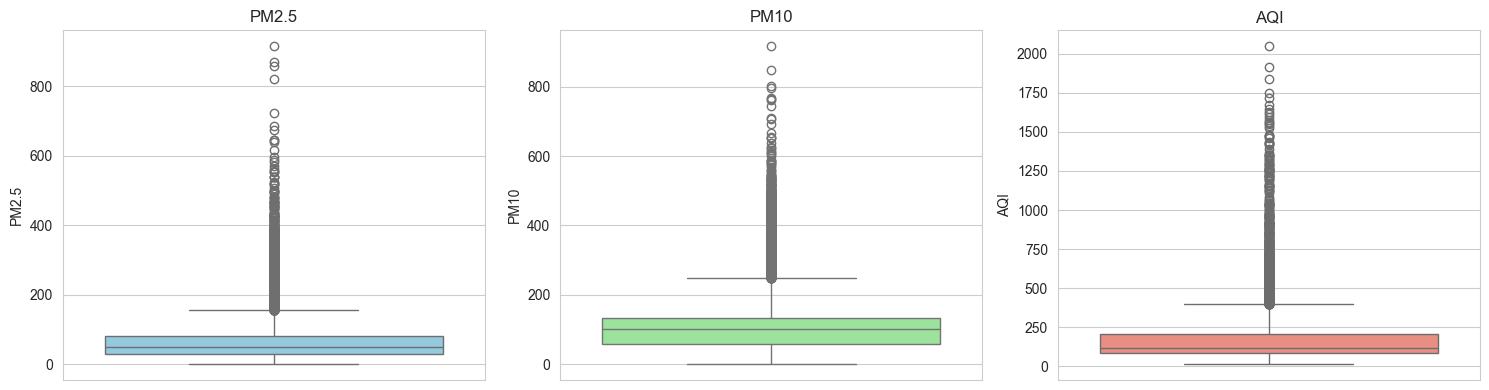

In [24]:
def iqr_outliers(col):
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((df[col] < low) | (df[col] > high)).sum()

outliers = pd.Series({c: iqr_outliers(c) for c in ['PM2.5', 'PM10', 'CO', 'AQI']})
print(outliers)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(y=df['PM2.5'], ax=axes[0], color='skyblue')
sns.boxplot(y=df['PM10'], ax=axes[1], color='lightgreen')
sns.boxplot(y=df['AQI'], ax=axes[2], color='salmon')
axes[0].set_title('PM2.5')
axes[1].set_title('PM10')
axes[2].set_title('AQI')
plt.tight_layout()
plt.show()


In [25]:
print('Final shape:', df.shape)
print('Total missing values:', df.isnull().sum().sum())
df.to_csv('city_day_clean.csv', index=False)


Final shape: (24850, 18)
Total missing values: 0


In [26]:
aqi = df['AQI'].values
print('Mean AQI   :', round(np.mean(aqi), 2))
print('Median AQI :', round(np.median(aqi), 2))
print('Std Dev    :', round(np.std(aqi), 2))
print('90th pct   :', round(np.percentile(aqi, 90), 2))
print('Max AQI    :', np.max(aqi))
print('Skewness   :', round(df['AQI'].skew(), 2))


Mean AQI   : 166.46
Median AQI : 118.0
Std Dev    : 140.69
90th pct   : 341.0
Max AQI    : 2049.0
Skewness   : 3.4


Least polluted cities:
City
Ernakulam             92.4
Thiruvananthapuram    75.9
Coimbatore            73.0
Shillong              53.8
Aizawl                34.8
Name: AQI, dtype: float64


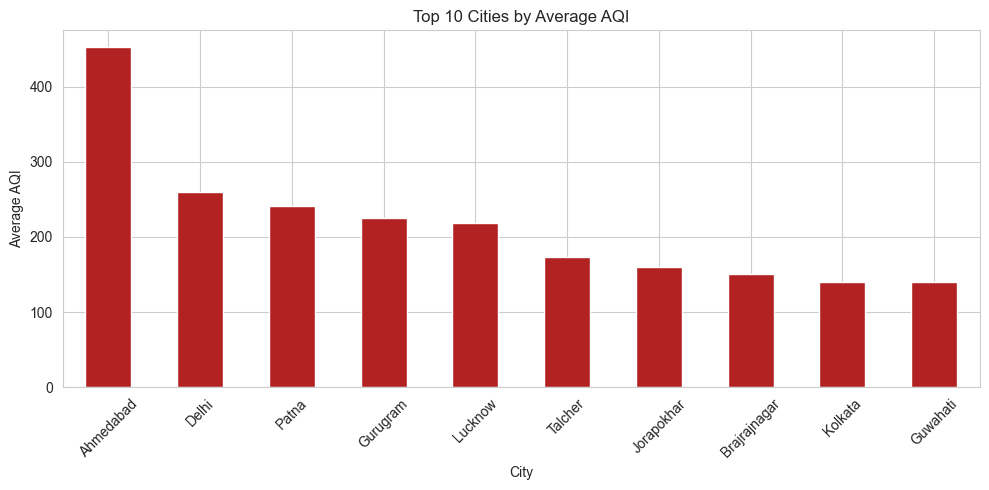

In [27]:
city_aqi = df.groupby('City')['AQI'].mean().sort_values(ascending=False)
print('Least polluted cities:')
print(city_aqi.tail(5).round(1))

city_aqi.head(10).plot(kind='bar', color='firebrick')
plt.title('Top 10 Cities by Average AQI')
plt.xlabel('City')
plt.ylabel('Average AQI')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


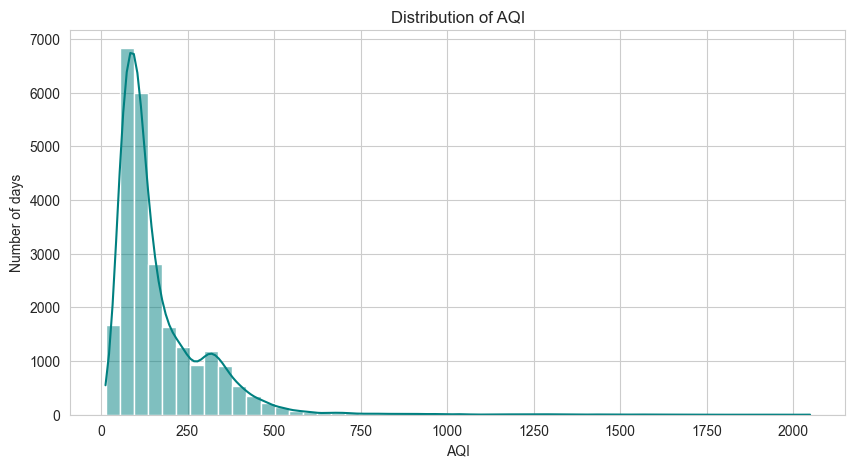

In [28]:
sns.histplot(df['AQI'], bins=50, kde=True, color='teal')
plt.title('Distribution of AQI')
plt.xlabel('AQI')
plt.ylabel('Number of days')
plt.show()


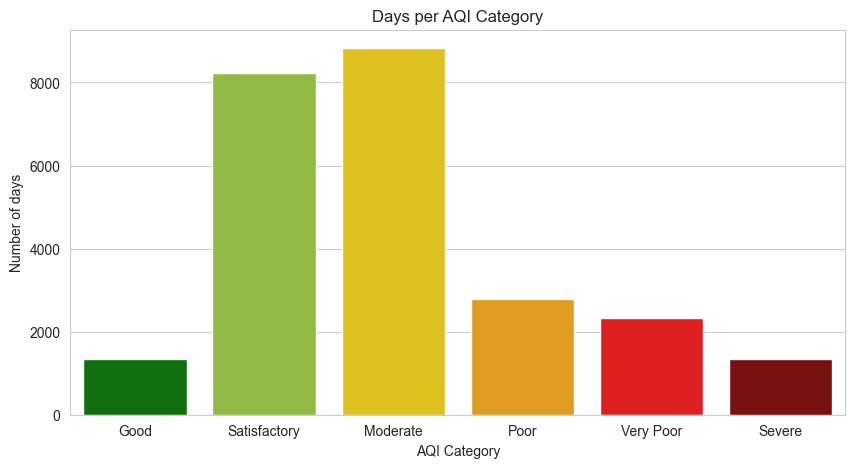

In [29]:
order = ['Good', 'Satisfactory', 'Moderate', 'Poor', 'Very Poor', 'Severe']
colors = ['green', 'yellowgreen', 'gold', 'orange', 'red', 'darkred']
sns.countplot(data=df, x='AQI_Bucket', order=order, palette=colors)
plt.title('Days per AQI Category')
plt.xlabel('AQI Category')
plt.ylabel('Number of days')
plt.show()


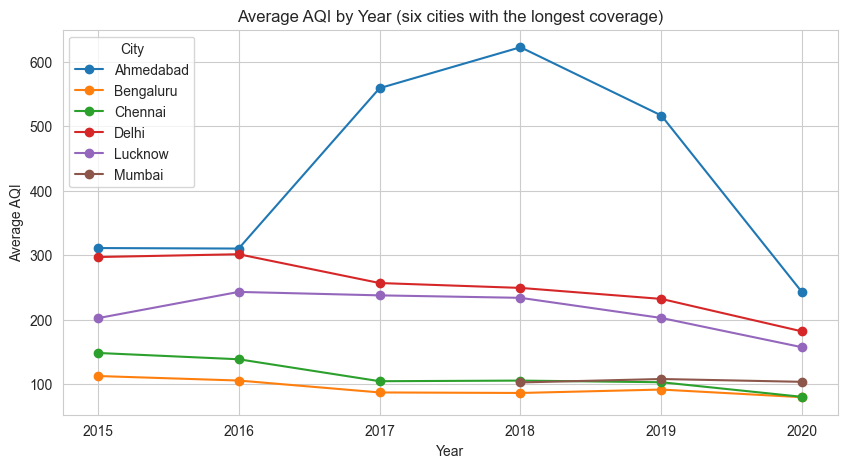

In [30]:
core = ['Ahmedabad', 'Bengaluru', 'Chennai', 'Delhi', 'Lucknow', 'Mumbai']
yearly = df[df['City'].isin(core)].groupby(['Year', 'City'])['AQI'].mean().unstack()

yearly.plot(marker='o', figsize=(10, 5))
plt.title('Average AQI by Year (six cities with the longest coverage)')
plt.xlabel('Year')
plt.ylabel('Average AQI')
plt.legend(title='City')
plt.show()



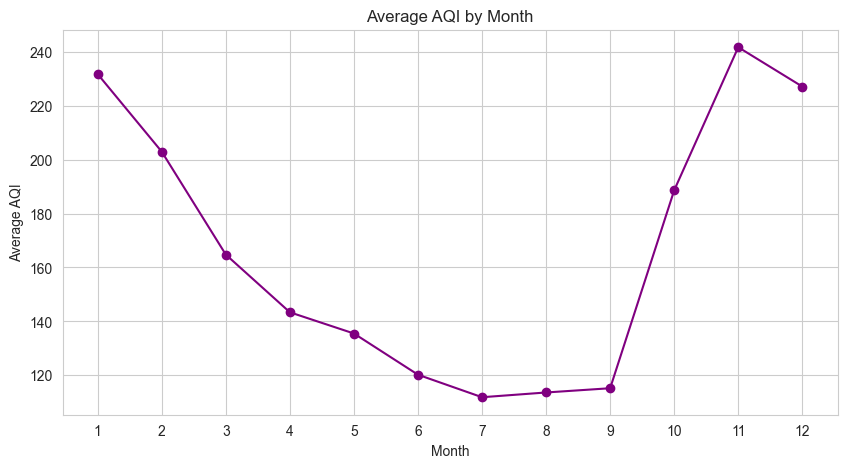

In [31]:
monthly = df.groupby('Month')['AQI'].mean()
monthly.plot(marker='o', color='purple', xticks=range(1, 13))
plt.title('Average AQI by Month')
plt.xlabel('Month')
plt.ylabel('Average AQI')
plt.show()


Season
Winter          220.6
Summer          147.7
Monsoon         115.6
Post-Monsoon    215.5
Name: AQI, dtype: float64


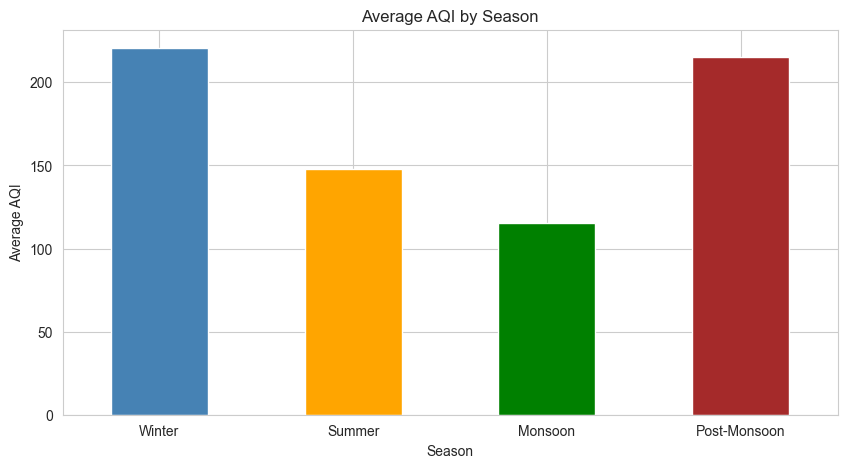

In [22]:
season_order = ['Winter', 'Summer', 'Monsoon', 'Post-Monsoon']
season_aqi = df.groupby('Season')['AQI'].mean().reindex(season_order)
print(season_aqi.round(1))

season_aqi.plot(kind='bar', color=['steelblue', 'orange', 'green', 'brown'])
plt.title('Average AQI by Season')
plt.ylabel('Average AQI')
plt.xticks(rotation=0)
plt.show()


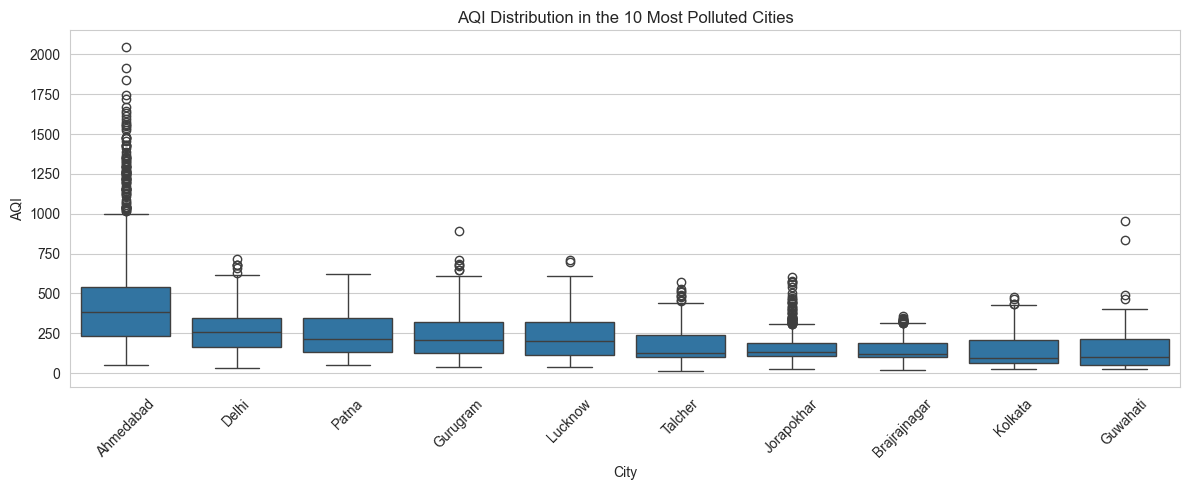

In [23]:
top10 = city_aqi.head(10).index.tolist()
plt.figure(figsize=(12, 5))
sns.boxplot(data=df[df['City'].isin(top10)], x='City', y='AQI', order=top10)
plt.title('AQI Distribution in the 10 Most Polluted Cities')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


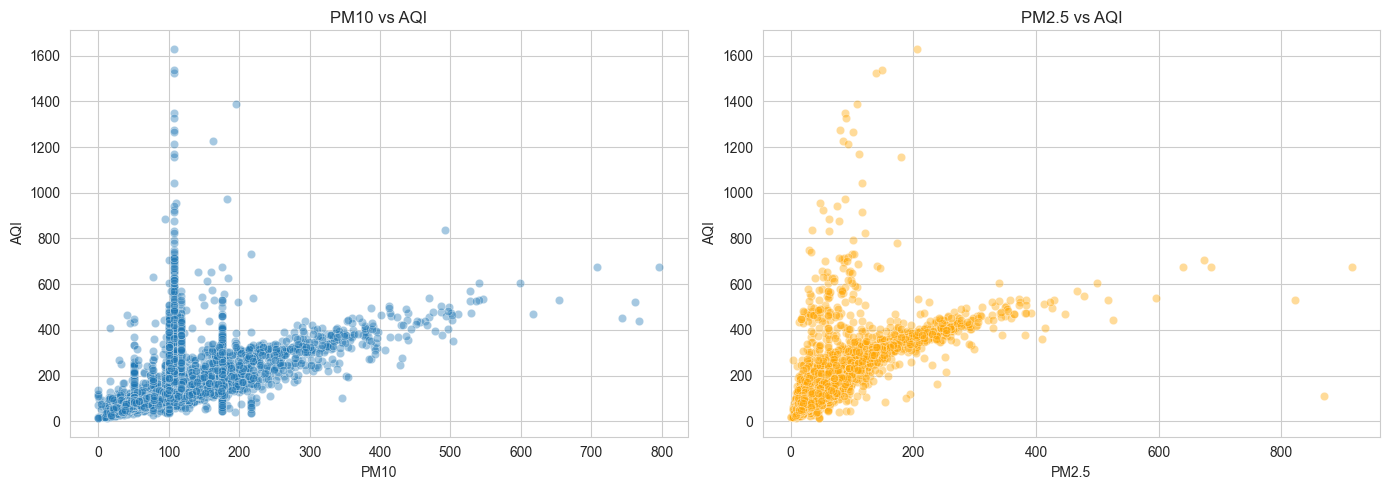

In [24]:
sample = df.sample(5000, random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=sample, x='PM10', y='AQI', alpha=0.4, ax=axes[0])
axes[0].set_title('PM10 vs AQI')
sns.scatterplot(data=sample, x='PM2.5', y='AQI', alpha=0.4, color='orange', ax=axes[1])
axes[1].set_title('PM2.5 vs AQI')
plt.tight_layout()
plt.show()


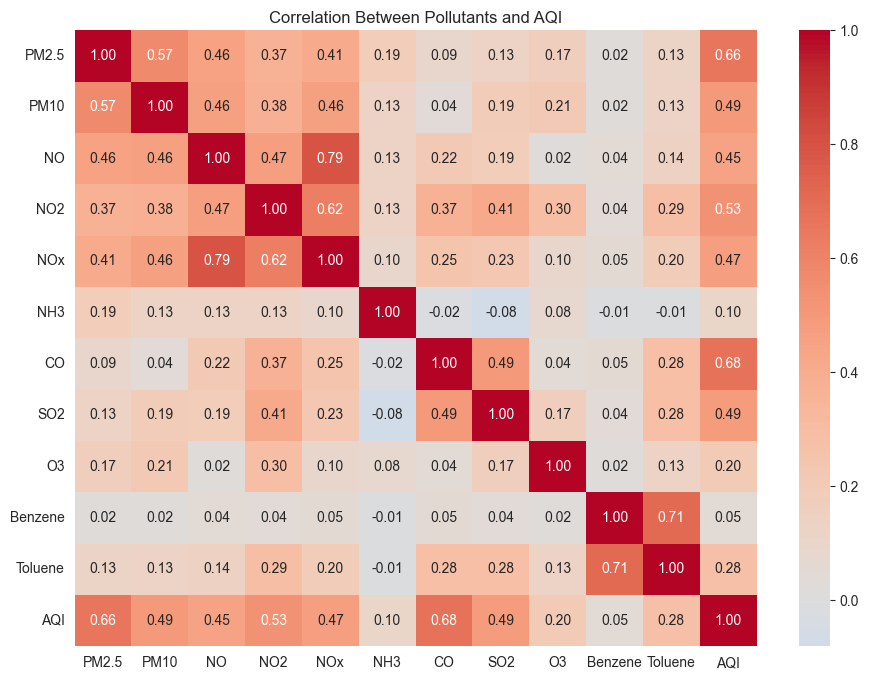

AQI        1.00
CO         0.68
PM2.5      0.66
NO2        0.53
PM10       0.49
SO2        0.49
NOx        0.47
NO         0.45
Toluene    0.28
O3         0.20
NH3        0.10
Benzene    0.05
Name: AQI, dtype: float64
NumPy check, PM10 vs AQI: 0.49


In [25]:
corr = df[pollutants + ['AQI']].corr()
plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Between Pollutants and AQI')
plt.show()

print(corr['AQI'].sort_values(ascending=False).round(2))
print('NumPy check, PM10 vs AQI:', round(np.corrcoef(df['PM10'], df['AQI'])[0, 1], 2))


Year        2019   2020
City                   
Ahmedabad  511.8  156.8
Bengaluru  105.7   72.1
Chennai    101.3   78.8
Delhi      212.7  131.0
Lucknow    196.9  114.3
Mumbai      95.5   74.2

Change in AQI (%), 2020 vs 2019:
City
Ahmedabad   -69.4
Bengaluru   -31.8
Chennai     -22.2
Delhi       -38.4
Lucknow     -41.9
Mumbai      -22.3
dtype: float64


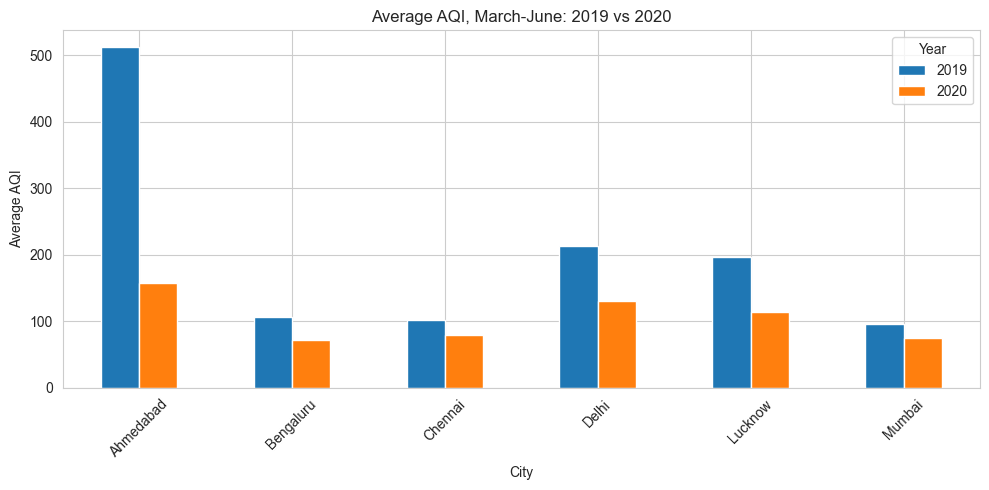

In [26]:
lock = df[df['City'].isin(core) & df['Month'].isin([3, 4, 5, 6]) & df['Year'].isin([2019, 2020])]
comp = lock.groupby(['City', 'Year'])['AQI'].mean().unstack()
print(comp.round(1))
print()
print('Change in AQI (%), 2020 vs 2019:')
print(((comp[2020] - comp[2019]) / comp[2019] * 100).round(1))

comp.plot(kind='bar', figsize=(10, 5))
plt.title('Average AQI, March-June: 2019 vs 2020')
plt.ylabel('Average AQI')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
